# Supplementary Figure 10 — rest-to-lick vs lick-during-locomotion

Ported from `step-3-revise-analyze-cm229-lick-during-rest.ipynb` (a rebuttal-era analysis
that lived outside this repository, in `~/Documents/Final_Rev/`). That notebook also built
example movies and several exploratory panels; only the code needed for the published
figure is kept here, rewritten against `paths.py` instead of the old
`/mnt/staging/users/wx2203/...` absolute paths.

**Caption.** *Comparison of rest-to-lick and locomotion-baselined licking.* Columns show two
conditions: (**a**) rest-to-lick — lick bouts beginning from a quiescent baseline (no
locomotion, forepaw, or postural movement in the window before lick onset; n = 40 bouts),
and (**b**) lick-during-locomotion — lick bouts during sustained locomotion (n = 19 bouts).
Rows (i–v) show the same measurements for each condition. All data are aligned to lick onset
(t = 0); dashed lines mark t1 = −0.5 s (pre-lick) and t2 = +0.5 s (during licking).
(**i**) Mean ± s.e.m. behavioral time courses. (**ii**) Trial-averaged Thy1-jRGECO ΔF/F maps
at t1 and t2, baseline-subtracted to the pre-lick window. (**iii**) As in (ii), for
GCaMP-labeled corticospinal neurons (CSN); green circle marks the right-forepaw M1 seed.
(**iv**) Mean ± s.e.m. CSN GCaMP ΔF/F at that seed. (**v**) Paired t1-vs-t2 comparison of
body PC and RFP-M1 CSN ΔF/F (Wilcoxon signed-rank).

## A note on the reported p-values — read before changing anything

The published panel (v) values were produced on the original analysis machine, whose
**scipy predates 1.9**. In those versions `wilcoxon(..., method='auto')` used the *normal
approximation* when n > 25 and the *exact* test otherwise. Modern scipy (≥1.9) raised that
threshold to n ≤ 50, so on this machine `'auto'` would use the **exact** test for both
conditions and return different numbers for the n = 40 column:

| panel (v) comparison | n | exact | approx | published caption |
|---|---|---|---|---|
| rest-to-lick / body PC | 40 | 7.28e-08 | **1.49e-06** | 1.5 × 10⁻⁶ |
| rest-to-lick / CSN RFP | 40 | 3.64e-12 | **3.85e-08** | 3.9 × 10⁻⁸ |
| lick-during-locomotion / body PC | 19 | **6.23e-01** | 6.01e-01 | 0.62 |
| lick-during-locomotion / CSN RFP | 19 | **3.74e-01** | 3.55e-01 | 0.37 |

The bout selection, epoch data and windows are **identical** either way (n = 40 and n = 19
both reproduce exactly, from 85 valid lick bouts) — only the tail probability differs.

**This notebook is set to `LEGACY_SCIPY_AUTO = False`** — the exact test throughout, which is
statistically preferable and is what current scipy does by default. The two rest-to-lick
p-values it reports are therefore *smaller* (more significant) than the ones in the original
caption; significance stars (`****`) and every conclusion are unchanged. The caption has been
updated to match.

Set the flag back to `True` to reproduce the original deposited figure and caption numbers
exactly, by emulating the old `'auto'` rule.

In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE

In [2]:
import glob
import pickle

import h5py
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import seaborn as sns          # registers the 'icefire' colormap used for the Thy1 maps
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
from scipy import stats
from scipy.stats import wilcoxon
from skimage import measure
from skimage.measure import regionprops
import scipy.ndimage as ndi

sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

MOUSE = 'cm229'
step_0_root = str(STEPS / 'step_0') + '/'
step_1_root = str(STEPS / 'step_1') + '/'
epochs_lick_root = str(PREPARES / 'epochs-licking') + '/'
figure_config_root = str(PREPARES / 'config') + '/'
fetch_path_M1 = str(PREPARES / 'index-M1') + '/'

HERE = CODE / 'make_1_figures' / 'figure_S10'
CACHE = FIGURES / 'figureS10'
CACHE.mkdir(parents=True, exist_ok=True)

## Configuration — every window and threshold from the original analysis

In [3]:
# --- False = exact test throughout (current scipy default; statistically preferable).
# True emulates the pre-1.9 scipy 'auto' rule that produced the original caption numbers.
LEGACY_SCIPY_AUTO = False

T_PRE, T_POST, fs = 90, 210, 15          # lick onset frame; frames after; Hz
t_ax = (np.arange(T_PRE + T_POST) - T_PRE) / fs

REST_WIN = range(T_PRE - 20, T_PRE)      # 2 s before onset that must be quiet
LICK_WIN = range(T_PRE, T_PRE + 7)       # ~0.5 s after onset (the lick itself)
bl       = range(T_PRE - 15, T_PRE - 5)  # pre-lick baseline for dF/F normalisation

T1_S, T2_S = -0.5, 0.5                   # the two comparison time points
T1_FR, T2_FR = int(np.round(T1_S * fs)), int(np.round(T2_S * fs))
STAT_WIN = 1                             # +/- 1 frame averaged around t1 / t2 for stats
MAP_WIN = 2                              # +/- 2 frames averaged for the brain maps
N_PRE_MAP, N_POST_MAP = 30, 18           # frames reconstructed around onset
XLIM, CSN_YLIM = [-1.0, 1.0], [-0.02, 0.05]

N_STATS = 40                             # size of the quiet rest-to-lick population
DS_FACTOR = 4                            # webcam 60 fps vs neural 15 fps
RFP_CSN_SEED = 322                       # right-forepaw CSN (gcamp) seed, 500-region parcellation

KEYS = ['M_jrgeco', 'M_gcamp', 'M_chbt', 'M_day_label', 'M_ind', 'M_licking',
        'M_is_groom', 'M_face_pc', 'M_body_pc', 'M_LFP_vel', 'M_RFP_vel', 'M_rotf']
BEH_LIST = ['M_licking', 'M_LFP_vel', 'M_RFP_vel', 'M_rotf', 'M_body_pc']


def wilcoxon_p(v2, v1):
    '''Signed-rank p-value. Emulates the original scipy's 'auto' (approx when n>25) when
    LEGACY_SCIPY_AUTO, else uses the exact test.'''
    n = int(np.sum(np.asarray(v2) - np.asarray(v1) != 0))
    method = 'approx' if (LEGACY_SCIPY_AUTO and n > 25) else 'exact'
    return wilcoxon(v2, v1, method=method)[1], method


def star(p):
    for thr, s in ((1e-4, '****'), (1e-3, '***'), (1e-2, '**'), (5e-2, '*')):
        if p < thr:
            return s
    return 'n.s.'

## Region map and bout selection

The rest-to-lick population is the `N_STATS` **quietest** valid lick bouts, ranked by a
z-scored sum of four pre-lick movement metrics (wheel, faster forepaw, body PC, face PC).
"Valid" means the animal was not already licking (`pre_lick < 0.3`) and did lick after onset
(`post_lick > 0.1`). The lick-during-locomotion population is every bout in the separate
`<mouse>_lick-during-run.mat` epoch file.

In [4]:
with h5py.File(step_0_root + MOUSE + '/idx_sorted_500_' + MOUSE + '.mat', 'r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T.astype(float)
    IDX_sorted[IDX_sorted == 0] = np.nan
    props = regionprops(np.nan_to_num(IDX_sorted).astype(int))
    node_coords = np.asarray([p.centroid for p in props], dtype=np.float32)
print('parcellation regions:', int(np.nanmax(IDX_sorted)), '| node_coords', node_coords.shape)

parcellation regions: 500 | node_coords (500, 2)


In [5]:
def zc(x):
    s = np.std(x)
    return (x - np.mean(x)) / s if s > 0 else np.zeros_like(x)

_raw = scipy.io.loadmat(epochs_lick_root + MOUSE + '_raw.mat')
R = {k: np.squeeze(_raw[k]) for k in KEYS}
R['M_ind'] = np.squeeze(R['M_ind'])

wheel = np.mean(np.abs(R['M_rotf'][REST_WIN, :]), axis=0)
paw = np.maximum(np.mean(np.abs(R['M_LFP_vel'][REST_WIN, :]), axis=0),
                 np.mean(np.abs(R['M_RFP_vel'][REST_WIN, :]), axis=0))
body = np.std(R['M_body_pc'][REST_WIN, :], axis=0)
face = np.std(R['M_face_pc'][REST_WIN, :], axis=0)
rest_score = zc(wheel) + zc(paw) + zc(body) + zc(face)      # lower = quieter pre-lick

pre_lick = np.mean(R['M_licking'][T_PRE - 15:T_PRE, :], axis=0)
post_lick = np.mean(R['M_licking'][LICK_WIN, :], axis=0)
valid = (pre_lick < 0.3) & (post_lick > 0.1)

cand = np.where(valid)[0]
cand = cand[np.argsort(rest_score[cand])]                    # quietest first
rest_bouts = list(cand[:N_STATS])

RUN = {k: np.squeeze(scipy.io.loadmat(epochs_lick_root + MOUSE + '_lick-during-run.mat')[k])
       for k in KEYS}
RUN['M_ind'] = np.squeeze(RUN['M_ind'])
run_bouts = list(range(RUN['M_licking'].shape[-1]))

print(f'raw lick bouts            : {R["M_licking"].shape[-1]}')
print(f'valid lick bouts          : {valid.sum()}')
print(f'rest-to-lick (quietest)   : n = {len(rest_bouts)}   <- caption says 40')
print(f'lick-during-locomotion    : n = {len(run_bouts)}   <- caption says 19')
assert len(rest_bouts) == 40, len(rest_bouts)
assert len(run_bouts) == 19, len(run_bouts)

raw lick bouts            : 88
valid lick bouts          : 85
rest-to-lick (quietest)   : n = 40   <- caption says 40
lick-during-locomotion    : n = 19   <- caption says 19


### Sanity check: the rest-to-lick bouts really are quiet before onset

The selection is only meaningful if the chosen bouts have near-zero pre-lick movement
relative to the population they were drawn from.

In [6]:
rows = []
for name, metric in (('wheel |speed|', wheel), ('faster forepaw |speed|', paw),
                     ('body PC s.d.', body), ('face PC s.d.', face)):
    rows.append({'pre-lick metric': name,
                 'selected 40 (mean)': metric[rest_bouts].mean(),
                 'all 88 bouts (mean)': metric.mean(),
                 'ratio selected/all': metric[rest_bouts].mean() / metric.mean()})
pd.DataFrame(rows).round(4)

,pre-lick metric,selected 40 (mean),all 88 bouts (mean),ratio selected/all
0,wheel |speed|,0.3684,0.5953,0.6189
1,faster forepaw |speed|,0.5851,0.9415,0.6214
2,body PC s.d.,0.1364,0.3078,0.4432
3,face PC s.d.,0.3490,0.4919,0.7095


## Behavioural and CSN time courses

In [7]:
def beh_avg(D, bouts, normalize):
    out = {}
    for nm in BEH_LIST:
        arr = D[nm][:, bouts].astype(float)
        if normalize:
            arr = arr - np.mean(arr[bl, :], axis=0, keepdims=True)
        out[nm] = (np.nanmean(arr, 1), stats.sem(arr, 1))
    return out


def seed_tc(M_gcamp, seed, bl_win):
    tc = M_gcamp[seed, :, :]
    return tc - np.mean(tc[bl_win, :], axis=0, keepdims=True)


def t1t2(arr2d):
    f1, f2 = T_PRE + T1_FR, T_PRE + T2_FR
    return (np.nanmean(arr2d[f1 - STAT_WIN:f1 + STAT_WIN + 1, :], 0),
            np.nanmean(arr2d[f2 - STAT_WIN:f2 + STAT_WIN + 1, :], 0))


beh_rest = beh_avg(R, rest_bouts, normalize=True)     # (a) baseline-normalised
beh_run = beh_avg(RUN, run_bouts, normalize=False)    # (b) un-normalised, locomotion continuous
csn_rest = seed_tc(R['M_gcamp'][:, :, rest_bouts], RFP_CSN_SEED, bl)
csn_run = seed_tc(RUN['M_gcamp'][:, :, run_bouts], RFP_CSN_SEED, bl)
print('csn_rest', csn_rest.shape, '| csn_run', csn_run.shape)

csn_rest (300, 40) | csn_run (300, 19)


## Panel (v) statistics — verified against the caption

In [8]:
# Revised caption values (exact test). The originals, from the pre-1.9-scipy 'auto' rule,
# were 1.5e-6 and 3.9e-8 for the two rest-to-lick rows; the n=19 rows are unchanged because
# 'auto' already used the exact test at that sample size.
CAPTION_P = {('rest-to-lick', 'body PC'): 7.3e-8, ('rest-to-lick', 'CSN RFP'): 3.6e-12,
             ('lick-during-locomotion', 'body PC'): 0.62,
             ('lick-during-locomotion', 'CSN RFP'): 0.37}
LEGACY_CAPTION_P = {('rest-to-lick', 'body PC'): 1.5e-6, ('rest-to-lick', 'CSN RFP'): 3.9e-8}

stat_rows = []
for cond, bodypc, csn in (('rest-to-lick', R['M_body_pc'][:, rest_bouts].astype(float), csn_rest),
                          ('lick-during-locomotion', RUN['M_body_pc'][:, run_bouts].astype(float), csn_run)):
    for lab, arr in (('body PC', bodypc), ('CSN RFP', csn)):
        v1, v2 = t1t2(arr)
        p, method = wilcoxon_p(v2, v1)
        p_exact = wilcoxon(v2, v1, method='exact')[1]
        p_approx = wilcoxon(v2, v1, method='approx')[1]
        stat_rows.append({
            'condition': cond, 'measure': lab, 'n bouts': arr.shape[1],
            'mean t1': v1.mean(), 'mean t2': v2.mean(), 'mean t2-t1': (v2 - v1).mean(),
            'p (reported)': p, 'method': method, 'significance': star(p),
            'p exact': p_exact, 'p approx': p_approx,
            'caption p': CAPTION_P[(cond, lab)]})
stats_df = pd.DataFrame(stat_rows)

ok = True
for _, r in stats_df.iterrows():
    match = f"{r['p (reported)']:.1e}" == f"{r['caption p']:.1e}"
    ok &= match
    print(f"{'OK  ' if match else 'FAIL'} {r['condition']:24s} {r['measure']:8s} "
          f"n={r['n bouts']:2d}  p={r['p (reported)']:.4e} ({r['method']:6s})  "
          f"caption {r['caption p']:.1e}  {r['significance']}")
print(f"\n{'all four p-values match the caption' if ok else '*** MISMATCH ***'}")
stats_df.round(6)

OK   rest-to-lick             body PC  n=40  p=7.2841e-08 (exact )  caption 7.3e-08  ****
OK   rest-to-lick             CSN RFP  n=40  p=3.6380e-12 (exact )  caption 3.6e-12  ****
OK   lick-during-locomotion   body PC  n=19  p=6.2256e-01 (exact )  caption 6.2e-01  n.s.
OK   lick-during-locomotion   CSN RFP  n=19  p=3.7360e-01 (exact )  caption 3.7e-01  n.s.

all four p-values match the caption


,condition,measure,n bouts,mean t1,mean t2,mean t2-t1,p (reported),method,significance,p exact,p approx,caption p
0,rest-to-lick,body PC,40,-0.470847,0.262045,0.732892,0.000000,exact,****,0.000000,0.000001,0.00
1,rest-to-lick,CSN RFP,40,-0.000468,0.045333,0.045801,0.000000,exact,****,0.000000,0.000000,0.00
2,lick-during-locomotion,body PC,19,1.551007,1.704468,0.153461,0.622562,exact,n.s.,0.622562,0.600871,0.62
3,lick-during-locomotion,CSN RFP,19,0.000900,0.004210,0.003310,0.373596,exact,n.s.,0.373596,0.354669,0.37


## Trial-averaged brain maps (rows ii–iii)

This is the expensive step: each bout's 256×256 jRGECO and GCaMP frames are rebuilt from the
`step_1` spatial/temporal factorisation (`S @ C`), baseline-subtracted to the pre-lick window,
then averaged over bouts at t1 and t2. Results are cached to
`figures_data/figureS10/` — delete that file to force a recompute.

In [9]:
def recon_both(session_id, ind):
    '''Rebuild 256x256 jrgeco + gcamp frames around one bout from step_1 factors.'''
    sid = str(session_id).split(' ')[0]
    day = sid.split(MOUSE + '_')[1].split('_')[0]
    run_id = sid.split(MOUSE + '_')[1].split('_')[1]
    f3 = sorted(set(glob.glob(step_1_root + MOUSE + '/' + day + '/*' + run_id + '*.mat')))[0]
    out = {}
    with h5py.File(f3, 'r') as f_H:
        nanidx = np.squeeze(f_H['m']['nanidx']) == 1
        for key in ('jrgeco', 'gcamp'):
            C = np.array(f_H['C'][key])
            S = np.array(f_H['S'][key])[ind - N_PRE_MAP:ind + N_POST_MAP, :]
            CS = np.dot(S, C).transpose()
            img = np.full((len(nanidx), CS.shape[-1]), np.nan)
            img[nanidx == True, :] = CS
            out[key] = img.reshape((256, 256, -1)).transpose((1, 0, 2))
    return out


def avg_maps(M_ind_arr, M_label_arr, bouts, tag=''):
    onset = N_PRE_MAP
    acc = {(k, t): [] for k in ('jrgeco', 'gcamp') for t in ('t1', 't2')}
    for n, b in enumerate(bouts):
        ind = int(M_ind_arr[b] / DS_FACTOR)
        cl = recon_both(str(M_label_arr[b]), ind)
        for key in ('jrgeco', 'gcamp'):
            clip = cl[key]
            # pre-lick baseline (~-1 to -0.33 s of the reconstructed clip)
            clip = clip - np.nanmean(clip[:, :, 15:25], axis=2, keepdims=True)
            for tn, fo in (('t1', T1_FR), ('t2', T2_FR)):
                fr = onset + fo
                acc[(key, tn)].append(np.nanmean(clip[:, :, fr - MAP_WIN:fr + MAP_WIN + 1], axis=2))
        if (n + 1) % 10 == 0:
            print(f'  {tag} {n + 1}/{len(bouts)} bouts', flush=True)
    return {k: np.nanmean(np.stack(v, 0), 0) for k, v in acc.items()}


cache_file = CACHE / f'maps_{MOUSE}_rest_vs_locomotion.pkl'
if cache_file.exists():
    with open(cache_file, 'rb') as f:
        maps_rest, maps_run = pickle.load(f)
    print(f'loaded cached maps: {cache_file}')
else:
    print(f'reconstructing REST maps for {len(rest_bouts)} bouts ...', flush=True)
    maps_rest = avg_maps(R['M_ind'], R['M_day_label'], rest_bouts, tag='rest')
    print(f'reconstructing LOCOMOTION maps for {len(run_bouts)} bouts ...', flush=True)
    maps_run = avg_maps(RUN['M_ind'], RUN['M_day_label'], run_bouts, tag='run')
    with open(cache_file, 'wb') as f:
        pickle.dump((maps_rest, maps_run), f)
    print(f'cached -> {cache_file}')
print({k: v.shape for k, v in maps_rest.items()})

loaded cached maps: /Volumes/WX/scratch/figures_data/figureS10/maps_cm229_rest_vs_locomotion.pkl
{('jrgeco', 't1'): (256, 256), ('jrgeco', 't2'): (256, 256), ('gcamp', 't1'): (256, 256), ('gcamp', 't2'): (256, 256)}


In [10]:
# midline mask -> NaN background, plus a brain outline for the map panels
with h5py.File(figure_config_root + 'mask_midline_v2_' + MOUSE + '.mat', 'r') as f_m:
    mask_midline = np.array(f_m['mask_midline']).T

brain_mask = np.isfinite(maps_rest[('jrgeco', 't2')]).astype(float)
filled_bw = ndi.binary_fill_holes(np.multiply(mask_midline, brain_mask) > 0.2)
brain_contours = measure.find_contours(filled_bw.astype(float), 0.8)


def apply_midline(maps):
    return {k: np.where(mask_midline < 0.5, np.nan, v) for k, v in maps.items()}


maps_rest = apply_midline(maps_rest)
maps_run = apply_midline(maps_run)
print('brain contours:', len(brain_contours))

brain contours: 2


## The figure

In [11]:
palatte_behavior_dict = load_pickle(figure_config_root + 'palatte_behavior_dict')
diverging_cmap_gcamp = load_pickle(figure_config_root + 'gcamp_diverging_cmap')

data_by_cond = {
    'rest-to-lick': dict(beh=beh_rest, maps=maps_rest, csn=csn_rest,
                         bodypc=R['M_body_pc'][:, rest_bouts].astype(float),
                         norm=True, color='crimson'),
    'lick-during-locomotion': dict(beh=beh_run, maps=maps_run, csn=csn_run,
                                   bodypc=RUN['M_body_pc'][:, run_bouts].astype(float),
                                   norm=False, color='steelblue'),
}

beh_palette = {'M_licking': palatte_behavior_dict.get('M_licking', 'red'),
               'M_LFP_vel': palatte_behavior_dict.get('M_LFP_vel', 'tab:orange'),
               'M_RFP_vel': palatte_behavior_dict.get('M_RFP_vel', 'tab:red'),
               'M_rotf': palatte_behavior_dict.get('M_rotf', 'tab:blue'),
               'M_body_pc': 'tab:purple'}

saved /Volumes/WX/code/code_ncomms_revision/make_1_figures/figure_S10/figS10-rest-to-lick-vs-lick-during-locomotion.svg


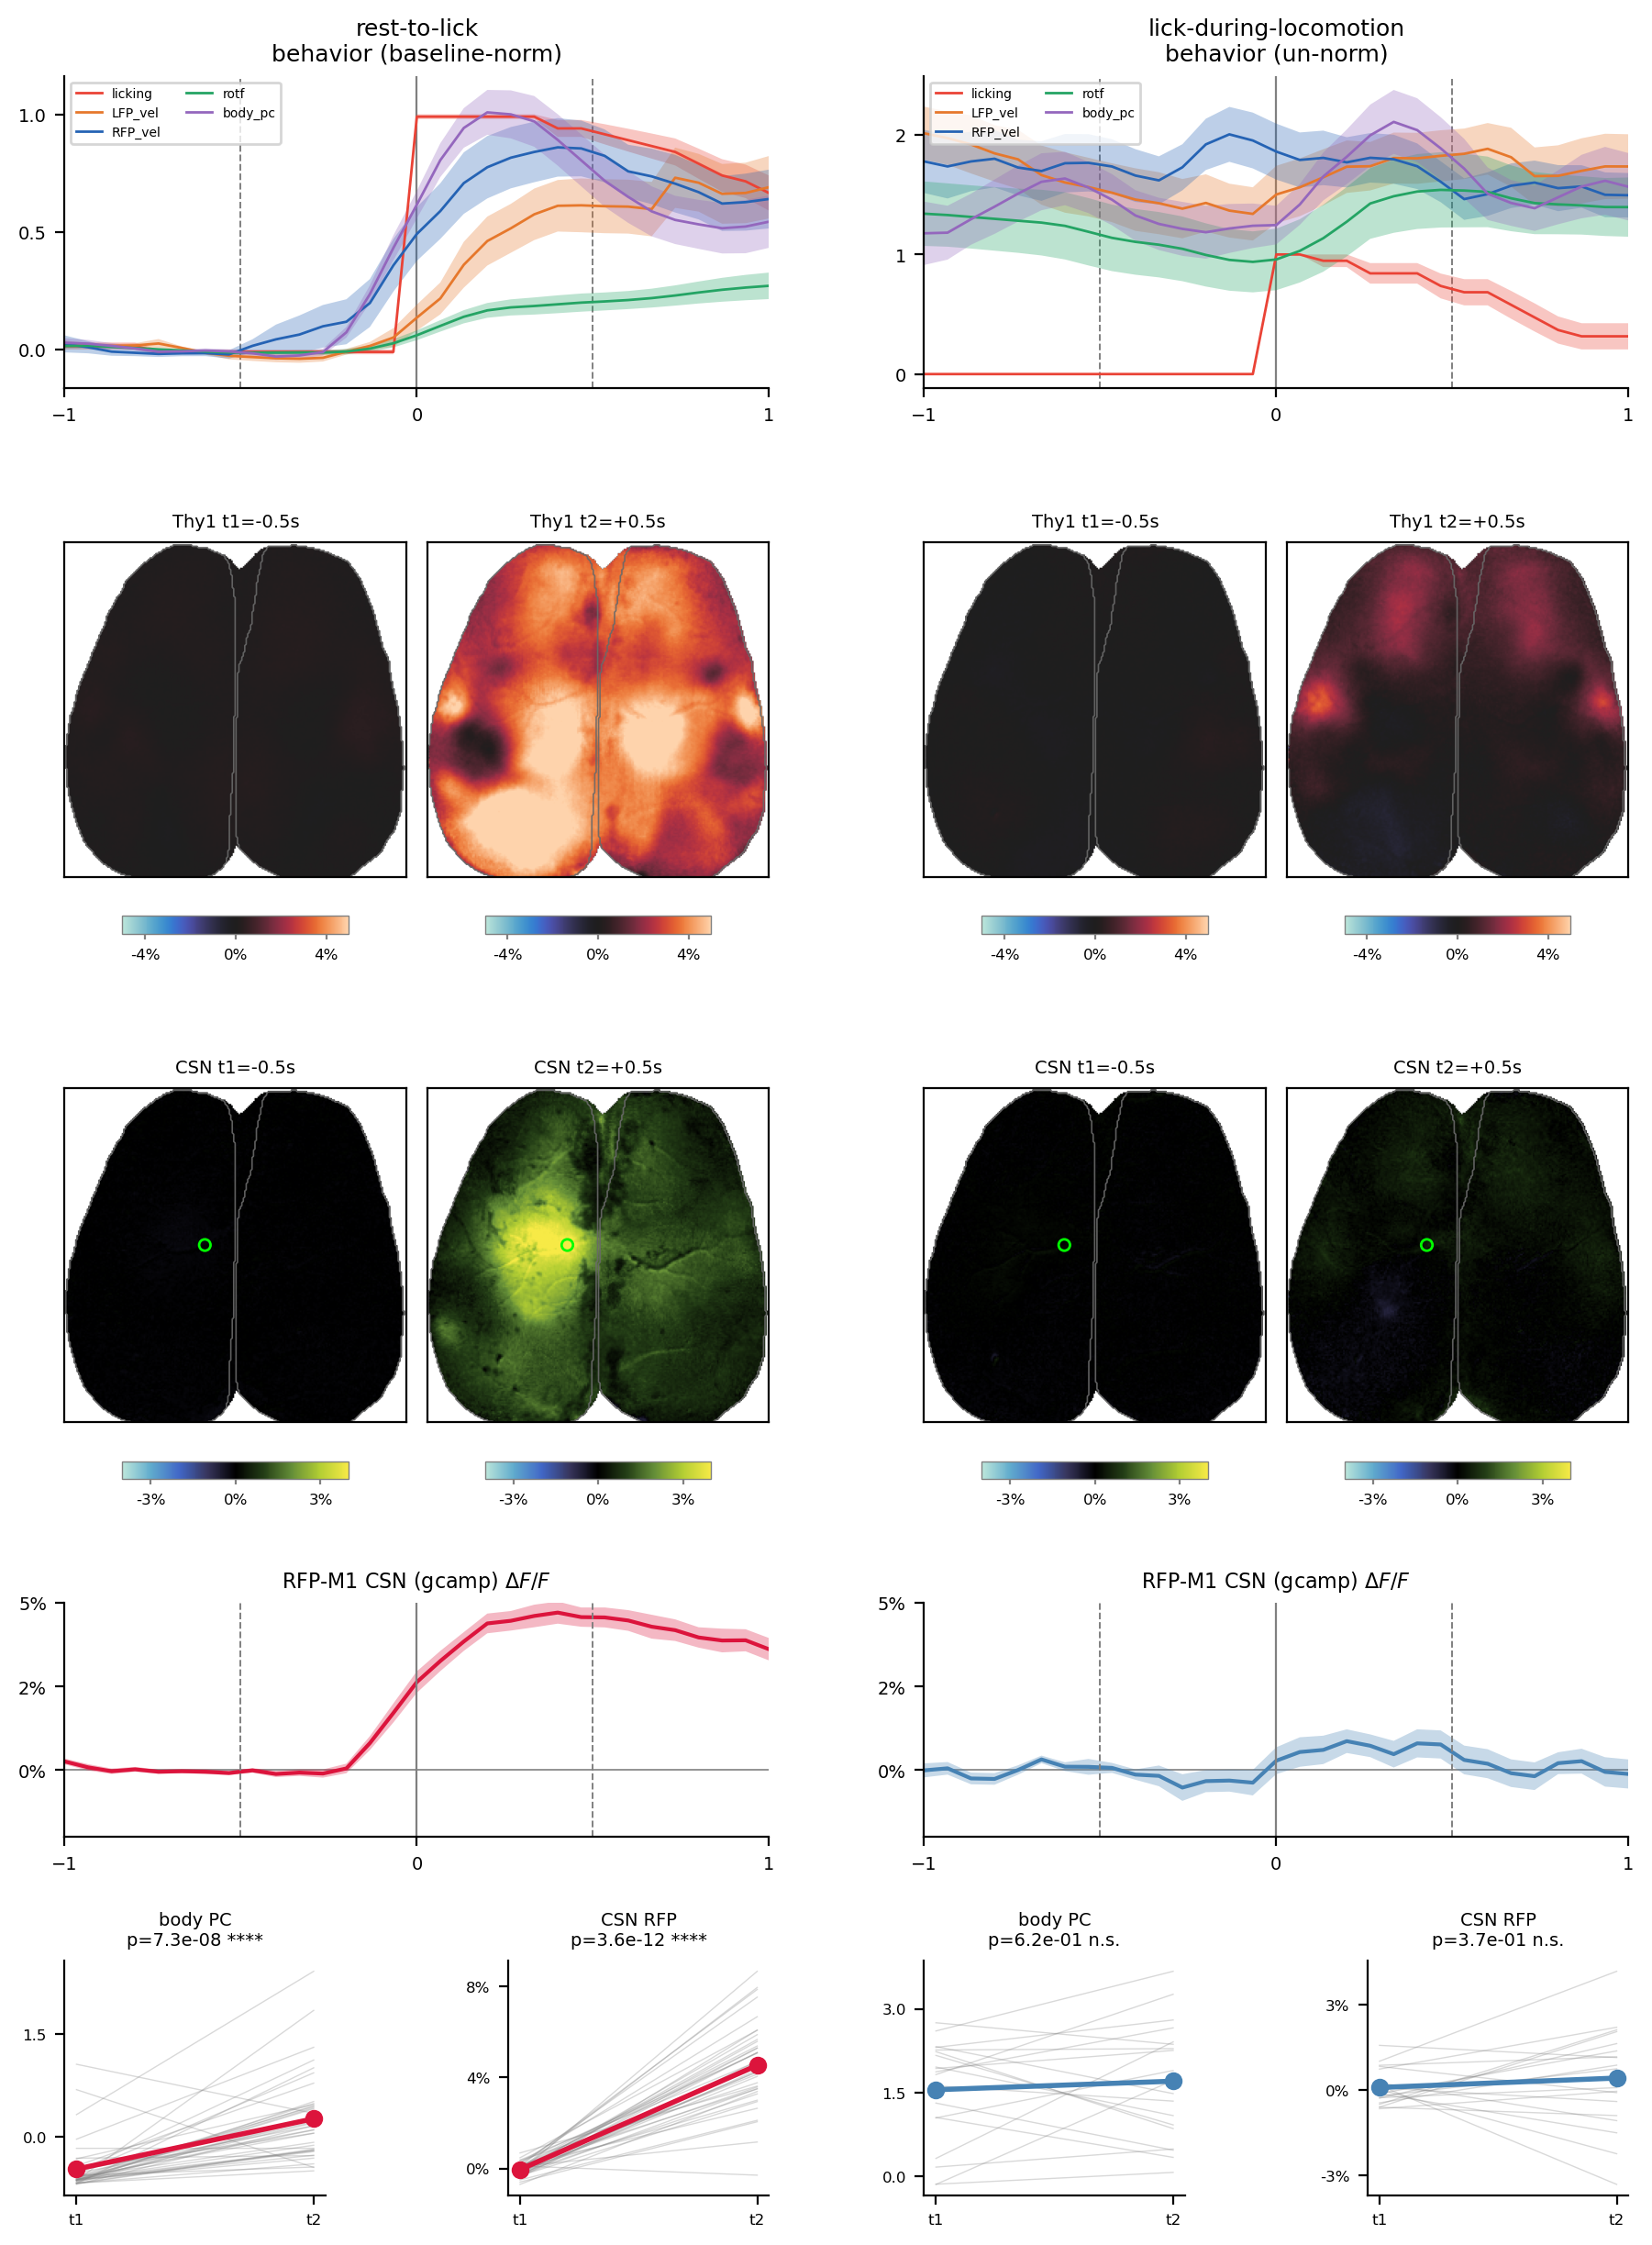

In [12]:
plt.rcParams['svg.fonttype'] = 'none'
fmt = lambda x, pos: '{:.0%}'.format(x)


def tidy_ticks(ax, xt=(-1, 0, 1)):
    ax.set_xticks(list(xt))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
    ax.tick_params(labelsize=7)


fig = plt.figure(figsize=(11, 15), dpi=200)
outer = fig.add_gridspec(1, 2, wspace=0.22)

for ci, (cond, dd) in enumerate(data_by_cond.items()):
    col = outer[0, ci].subgridspec(5, 1, height_ratios=[2.0, 2.7, 2.7, 1.5, 1.5], hspace=0.38)

    # (i) behaviour
    axb = fig.add_subplot(col[0])
    for nm in BEH_LIST:
        avg, sem = dd['beh'][nm]
        axb.plot(t_ax, avg, color=beh_palette[nm], lw=1, label=nm[2:])
        axb.fill_between(t_ax, avg - sem, avg + sem, color=beh_palette[nm], alpha=0.3, lw=0)
    axb.set_xlim(XLIM)
    axb.axvline(0, color='gray', lw=0.8, zorder=-9)
    for tt in (T1_S, T2_S):
        axb.axvline(tt, color='gray', ls='--', lw=0.7, zorder=-9)
    axb.set_title(f'{cond}\nbehavior ({"baseline-norm" if dd["norm"] else "un-norm"})', fontsize=9)
    axb.legend(fontsize=5, ncol=2, loc='upper left')
    tidy_ticks(axb)
    for s in ('top', 'right'):
        axb.spines[s].set_visible(False)

    # (ii) Thy1 maps and (iii) CSN maps
    for row, chan, clab, vlim, cmap_here in ((1, 'jrgeco', 'Thy1', 0.05, 'icefire'),
                                             (2, 'gcamp', 'CSN', 0.04, diverging_cmap_gcamp)):
        sub = col[row].subgridspec(2, 2, height_ratios=[22, 1], hspace=0.04, wspace=0.06)
        for j, tn in enumerate(('t1', 't2')):
            a = fig.add_subplot(sub[0, j])
            im = a.imshow(dd['maps'][(chan, tn)], vmin=-vlim, vmax=vlim, cmap=cmap_here)
            for ct in brain_contours:
                a.plot(ct[:, 1], ct[:, 0], lw=0.6, color='dimgray', alpha=0.9)
            if chan == 'gcamp':
                a.scatter(node_coords[RFP_CSN_SEED, 1], node_coords[RFP_CSN_SEED, 0],
                          s=20, facecolors='none', edgecolors='lime', lw=1)
            a.set_xlim([21, 256]); a.set_ylim([248, 18])
            a.set_xticks([]); a.set_yticks([])
            a.set_title(f'{clab} {"t1=-0.5s" if tn == "t1" else "t2=+0.5s"}', fontsize=7)
            cbslot = sub[1, j].subgridspec(1, 3, width_ratios=[1, 6, 1])
            cax = fig.add_subplot(cbslot[0, 1])
            cb = fig.colorbar(im, cax=cax, orientation='horizontal', format=FuncFormatter(fmt))
            cb.ax.tick_params(labelsize=6, length=2, color='gray')
            cb.outline.set_edgecolor('gray'); cb.outline.set_linewidth(0.5)
            cb.locator = ticker.MaxNLocator(nbins=3); cb.update_ticks()

    # (iv) RFP-M1 CSN time course
    axc = fig.add_subplot(col[3])
    m, s = np.nanmean(dd['csn'], 1), stats.sem(dd['csn'], 1)
    axc.plot(t_ax, m, color=dd['color'])
    axc.fill_between(t_ax, m - s, m + s, color=dd['color'], alpha=0.3, lw=0)
    axc.set_xlim(XLIM); axc.set_ylim(CSN_YLIM)
    axc.axvline(0, color='gray', lw=0.8)
    for tt in (T1_S, T2_S):
        axc.axvline(tt, color='gray', ls='--', lw=0.7)
    axc.axhline(0, color='gray', lw=0.6, zorder=-9)
    axc.yaxis.set_major_formatter(FuncFormatter(fmt))
    axc.set_title(r'RFP-M1 CSN (gcamp) $\Delta F/F$', fontsize=8)
    tidy_ticks(axc)
    for s_ in ('top', 'right'):
        axc.spines[s_].set_visible(False)

    # (v) paired t1 vs t2
    sub = col[4].subgridspec(1, 2, wspace=0.7)
    for j, (lab, arr) in enumerate((('body PC', dd['bodypc']), ('CSN RFP', dd['csn']))):
        ax = fig.add_subplot(sub[0, j])
        v1, v2 = t1t2(arr)
        for a_, b_ in zip(v1, v2):
            ax.plot([0, 1], [a_, b_], color='gray', alpha=.3, lw=.5)
        ax.plot([0, 1], [np.nanmean(v1), np.nanmean(v2)], color=dd['color'], lw=2, marker='o')
        p, _ = wilcoxon_p(v2, v1)
        ax.set_xticks([0, 1]); ax.set_xticklabels(['t1', 't2'], fontsize=7)
        ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
        if lab == 'CSN RFP':
            ax.yaxis.set_major_formatter(FuncFormatter(fmt))
        ax.set_title(f'{lab}\np={p:.1e} {star(p)}', fontsize=7)
        ax.tick_params(labelsize=6)
        for s_ in ('top', 'right'):
            ax.spines[s_].set_visible(False)

out_svg = HERE / 'figS10-rest-to-lick-vs-lick-during-locomotion.svg'
plt.savefig(out_svg, format='svg', dpi=300, bbox_inches='tight')
print('saved', out_svg)
plt.show()

## Source Data

Writes the per-bout values behind panels (iv)/(v) and the time courses behind (i)/(iv) to
`figures_data/figureS10/figS10_source_data.pkl`, which the Source Data workbook build reads to
build the "Supplementary Figure 10" sheet.

In [13]:
per_bout_rows = []
for cond, bodypc, csn in (('rest-to-lick', R['M_body_pc'][:, rest_bouts].astype(float), csn_rest),
                          ('lick-during-locomotion', RUN['M_body_pc'][:, run_bouts].astype(float), csn_run)):
    b1, b2 = t1t2(bodypc)
    c1, c2 = t1t2(csn)
    for i in range(len(b1)):
        per_bout_rows.append({'condition': cond, 'bout': i,
                              'body PC t1': b1[i], 'body PC t2': b2[i],
                              'body PC t2-t1': b2[i] - b1[i],
                              'CSN RFP dF/F t1': c1[i], 'CSN RFP dF/F t2': c2[i],
                              'CSN RFP dF/F t2-t1': c2[i] - c1[i]})
per_bout = pd.DataFrame(per_bout_rows)

tc_rows = []
for cond, dd in data_by_cond.items():
    csn_m, csn_s = np.nanmean(dd['csn'], 1), stats.sem(dd['csn'], 1)
    for i, t in enumerate(t_ax):
        if not (XLIM[0] <= t <= XLIM[1]):
            continue
        row = {'condition': cond, 'time from lick onset (s)': t,
               'CSN RFP dF/F mean': csn_m[i], 'CSN RFP dF/F s.e.m.': csn_s[i]}
        for nm in BEH_LIST:
            avg, sem = dd['beh'][nm]
            row[f'{nm[2:]} mean'] = avg[i]
            row[f'{nm[2:]} s.e.m.'] = sem[i]
        tc_rows.append(row)
time_courses = pd.DataFrame(tc_rows)

bundle = {'stats': stats_df, 'per_bout': per_bout, 'time_courses': time_courses,
          'n_bouts': {'rest-to-lick': len(rest_bouts), 'lick-during-locomotion': len(run_bouts)},
          'rest_bout_indices': list(map(int, rest_bouts)),
          'legacy_scipy_auto': LEGACY_SCIPY_AUTO}
out_pkl = CACHE / 'figS10_source_data.pkl'
with open(out_pkl, 'wb') as f:
    pickle.dump(bundle, f)
print(f'wrote {out_pkl}')
print(f'  stats {stats_df.shape} | per_bout {per_bout.shape} | time_courses {time_courses.shape}')
per_bout.head()

wrote /Volumes/WX/scratch/figures_data/figureS10/figS10_source_data.pkl
  stats (4, 12) | per_bout (59, 8) | time_courses (62, 14)


,condition,bout,body PC t1,body PC t2,body PC t2-t1,CSN RFP dF/F t1,CSN RFP dF/F t2,CSN RFP dF/F t2-t1
0,rest-to-lick,0,-0.674920,-0.394373,0.280547,-0.002042,0.032758,0.034800
1,rest-to-lick,1,-0.574172,0.439189,1.013361,0.000049,0.052938,0.052889
2,rest-to-lick,2,-0.321617,0.468775,0.790392,-0.003131,0.035055,0.038186
3,rest-to-lick,3,-0.623231,-0.269498,0.353733,0.000888,0.044244,0.043356
4,rest-to-lick,4,-0.599737,0.482459,1.082196,-0.002199,0.052864,0.055063
